# Lab4 METR-LA — Backtesting và đánh giá

**Người nhận:** TV6

**Nhiệm vụ:** Protocol chung, backtesting multi-horizon, mask/metrics và bảng so sánh VAR/XGBoost/LSTM.

**Phụ thuộc:** Chuẩn bị schema/metrics ngay; kết quả cuối chờ adapters của TV3/TV4/TV5.

**Bàn giao:** Predictions gắn origin/target/sensor/horizon, RMSE/MAE/MAPE theo horizon, valid counts, đồ thị và nhận xét.

Hạn bàn giao: Đã hoàn thành.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5`. Đã có dữ liệu, không phải tìm/tải hoặc ghép weather.
- 207 sensor, 5 phút/mẫu. Giữ nguyên thứ tự sensor và timestamps.
- Horizon 3/6/12 bước = 15/30/60 phút. Input lookback L cần chốt với leader theo DATA_CONTRACT.
- Split theo thời gian 70/15/15; scaler chỉ fit train; không tuning bằng test.
- Mask cho tốc độ 0/gần 0 phải có chính sách chung. Đánh giá cùng origin/sensor/horizon/thang đo.
- Code vẫn TODO. Không bàn giao một biến trong kernel; gửi code/config/schema và kết quả tái tạo được.

In [1]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR
import xgboost as xgb

warnings.filterwarnings("ignore")

# Tự động phát hiện thư mục gốc của repo (tương thích khi chạy từ root hoặc từ contributions/)
ROOT = Path.cwd()
if not (ROOT / "data/traffic/METR-LA.h5").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/traffic/METR-LA.h5"
MANIFEST_PATH = ROOT / "data/traffic/manifest.json"
TABLES_DIR = ROOT / "tables"
FIGURES_DIR = ROOT / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình protocol chung theo DATA_CONTRACT.md và thống nhất với TV2/TV3/TV4/TV5
CONFIG = {
    "dataset": "METR-LA",
    "sensors": ["773869", "767541", "767542", "717447", "717446"],
    "lookback_L": 12,               # 12 bước * 5 phút = 60 phút lịch sử
    "horizons": [3, 6, 12],         # Dự báo tại t+3 (15p), t+6 (30p), t+12 (60p)
    "step_minutes": 5,
    "split_ratios": (0.70, 0.15, 0.15),
    "warmup_steps": 35,             # Đảm bảo đủ 36 quan sát (t-35..t) cho rolling std 3 giờ (36 bước)
    "mask_policy": "y_true > 0",    # Loại bỏ các điểm tốc độ = 0 (sensor mất tín hiệu) khi tính lỗi
    "unit": "mph",
    "seed": 42,
}

# Xác thực SHA-256 và đọc dữ liệu gốc từ HDF5
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha256 == manifest["sha256"], "SHA-256 của file METR-LA.h5 không khớp manifest!"

with h5py.File(DATA_PATH, "r") as f:
    raw_values = f["df/block0_values"][:]
    raw_times = pd.to_datetime(f["df/axis1"][:])
    all_sensors = [s.decode("utf-8") if isinstance(s, bytes) else str(s) for s in f["df/axis0"][:]]

df_full = pd.DataFrame(raw_values, index=raw_times, columns=all_sensors)
assert df_full.shape == (34272, 207), f"Kích thước sai lệch: {df_full.shape}"
assert df_full.index.is_monotonic_increasing and df_full.index.duplicated().sum() == 0
assert int((df_full.values == 0).sum()) == manifest["zero_values"]

SENSORS = CONFIG["sensors"]
L = CONFIG["lookback_L"]
HORIZONS = CONFIG["horizons"]
UNIT = CONFIG["unit"]
MASK_POLICY = CONFIG["mask_policy"]
SEED = CONFIG["seed"]

df = df_full[SENSORS].copy()

print(f"Xác nhận file gốc: {DATA_PATH.name} | SHA-256: PASS")
print(f"Toàn mạng: {df_full.shape} | Khoảng thời gian: {df_full.index[0]} -> {df_full.index[-1]}")
print(f"Tổng số giá trị 0 toàn mạng: {int((df_full.values == 0).sum()):,} ({(df_full.values == 0).mean()*100:.2f}%)")
print(f"Tập sensor đánh giá chung ({len(SENSORS)} sensors): {SENSORS}")
print(f"Số giá trị 0 trong 5 sensors: {int((df.values == 0).sum()):,} / {df.size:,} ({(df.values == 0).mean()*100:.2f}%)")

Xác nhận file gốc: METR-LA.h5 | SHA-256: PASS
Toàn mạng: (34272, 207) | Khoảng thời gian: 2012-03-01 00:00:00 -> 2012-06-27 23:55:00
Tổng số giá trị 0 toàn mạng: 575,302 (8.11%)
Tập sensor đánh giá chung (5 sensors): ['773869', '767541', '767542', '717447', '717446']
Số giá trị 0 trong 5 sensors: 12,778 / 171,360 (7.46%)


## 1. Protocol và schema

Chốt rolling origins; tại mỗi origin forecast trọn 3/6/12 bước không dùng actual tương lai trong horizon. Mô hình/scaler cố định trong lượt test trừ khi đã thống nhất refit protocol khác.

In [2]:
# 1. Phân chia Train / Validation / Test theo thứ tự thời gian (70% / 15% / 15%)
T, N = df.shape
n_train = int(T * CONFIG["split_ratios"][0])
n_val = int(T * CONFIG["split_ratios"][1])
n_test = T - n_train - n_val

# 2. Thiết lập Rolling Origins (Walk-forward fixed-origin protocol)
# Chặn các origin cuối mỗi tập để target xa nhất (t + 12) không vượt sang tập kế tiếp (chống Data Leakage)
max_h = max(HORIZONS)
start_idx = CONFIG["warmup_steps"]  # t >= 35 để đủ cửa sổ rolling 36 bước (3 giờ)

train_origins = np.arange(start_idx, n_train - max_h)
val_origins = np.arange(n_train, n_train + n_val - max_h)
test_origins = np.arange(n_train + n_val, T - max_h)

# Kiểm định chống rò rỉ dữ liệu (Zero-Leakage Assertions)
assert train_origins[-1] + max_h < n_train, "Leakage: nhãn Train tràn sang Validation!"
assert val_origins[-1] + max_h < n_train + n_val, "Leakage: nhãn Validation tràn sang Test!"
assert test_origins[-1] + max_h < T, "Origin vượt quá chiều dài chuỗi!"
assert np.all(np.diff(test_origins) == 1), "Rolling origins trên tập Test phải liên tục từng bước 5 phút!"

# 3. Chuẩn hóa dữ liệu: StandardScaler chỉ fit trên tập Train
scaler = StandardScaler()
scaler.fit(df.iloc[:n_train].values)
scaled_vals = scaler.transform(df.values)
df_scaled = pd.DataFrame(scaled_vals, index=df.index, columns=SENSORS)

# Bản làm sạch nhân quả (causal forward-fill + train median) chỉ dùng cho chuỗi đầu vào của VAR/LSTM
# nhằm tránh hiện tượng tốc độ = 0 (mất tín hiệu) trong lịch sử làm biến dạng trạng thái tuyến tính/ẩn.
# Lưu ý: Nhãn đánh giá y_true luôn giữ nguyên giá trị gốc chưa nội suy và lọc bằng valid_mask (y_true > 0).
train_medians = df.iloc[:n_train].where(df.iloc[:n_train] > 0).median()
df_causal_clean = df.where(df > 0, np.nan).ffill().fillna(train_medians)
causal_scaled_vals = scaler.transform(df_causal_clean.values)

# 4. Định nghĩa Schema & Hàm kiểm tra hợp đồng dữ liệu (DATA_CONTRACT.md)
PREDICTION_COLUMNS = [
    "dataset", "model", "origin", "target_timestamp",
    "horizon_steps", "sensor_id", "y_true", "y_pred", "unit", "valid_mask"
]
METRIC_COLUMNS = [
    "model", "horizon_steps", "horizon_minutes", "n_eval",
    "RMSE", "MAE", "MAPE_pct", "mask_policy", "unit"
]

def validate_predictions_schema(df_pred: pd.DataFrame) -> None:
    assert list(df_pred.columns) == PREDICTION_COLUMNS, f"Sai cột predictions: {list(df_pred.columns)}"
    assert not df_pred[["y_true", "y_pred"]].isna().any().any(), "Có NaN trong y_true hoặc y_pred!"
    assert set(df_pred["horizon_steps"].unique()) == set(HORIZONS), "Thiếu horizon trong predictions!"
    assert df_pred["valid_mask"].dtype == bool, "valid_mask phải có kiểu bool!"

def validate_metrics_schema(df_met: pd.DataFrame) -> None:
    assert list(df_met.columns) == METRIC_COLUMNS, f"Sai cột metrics: {list(df_met.columns)}"
    assert not df_met[["RMSE", "MAE", "MAPE_pct"]].isna().any().any(), "Có NaN trong bảng metrics!"
    assert (df_met["n_eval"] > 0).all(), "Số mẫu hợp lệ n_eval phải > 0!"

split_summary = pd.DataFrame([
    {
        "Split": "Train (70%)",
        "Raw_Rows": n_train,
        "Num_Origins": len(train_origins),
        "First_Origin": str(df.index[train_origins[0]]),
        "Last_Origin": str(df.index[train_origins[-1]]),
        "Max_Target_(t+12)": str(df.index[train_origins[-1] + max_h]),
    },
    {
        "Split": "Validation (15%)",
        "Raw_Rows": n_val,
        "Num_Origins": len(val_origins),
        "First_Origin": str(df.index[val_origins[0]]),
        "Last_Origin": str(df.index[val_origins[-1]]),
        "Max_Target_(t+12)": str(df.index[val_origins[-1] + max_h]),
    },
    {
        "Split": "Test (15%)",
        "Raw_Rows": n_test,
        "Num_Origins": len(test_origins),
        "First_Origin": str(df.index[test_origins[0]]),
        "Last_Origin": str(df.index[test_origins[-1]]),
        "Max_Target_(t+12)": str(df.index[test_origins[-1] + max_h]),
    },
])

print("Bảng tổng hợp ranh giới Split & Rolling Origins (đảm bảo không tràn nhãn qua ranh giới):")
print(split_summary.to_string(index=False))

Bảng tổng hợp ranh giới Split & Rolling Origins (đảm bảo không tràn nhãn qua ranh giới):
           Split  Raw_Rows  Num_Origins        First_Origin         Last_Origin   Max_Target_(t+12)
     Train (70%)     23990        23943 2012-03-01 02:55:00 2012-05-23 06:05:00 2012-05-23 07:05:00
Validation (15%)      5140         5128 2012-05-23 07:10:00 2012-06-10 02:25:00 2012-06-10 03:25:00
      Test (15%)      5142         5130 2012-06-10 03:30:00 2012-06-27 22:55:00 2012-06-27 23:55:00


**Kết quả/nhận xét/bàn giao:**
- **Thiết lập রanh giới thời gian (70/15/15) & Chống rò rỉ (No Leakage):**
  - **Train:** `23.990` mẫu thô (`23.943` origins hợp lệ từ `2012-03-01 02:55:00` đến `2012-05-23 06:05:00`, nhãn xa nhất `t+12` tại `2012-05-23 07:05:00` nằm gọn trong tập Train).
  - **Validation:** `5.140` mẫu thô (`5.128` origins hợp lệ từ `2012-05-23 07:10:00` đến `2012-06-10 02:25:00`, nhãn xa nhất `t+12` tại `2012-06-10 03:25:00`).
  - **Test:** `5.142` mẫu thô (`5.130` rolling origins liên tiếp từ `2012-06-10 03:30:00` đến `2012-06-27 22:55:00`, nhãn xa nhất `t+12` tại `2012-06-27 23:55:00`).
- **Quy tắc Fixed-Origin Multi-Step Backtesting:** Tại mỗi thời điểm gốc `origin = t` trên tập Test, các mô hình chỉ được phép truy cập lịch sử `<= t` để dự báo đồng thời `t+3` (15 phút), `t+6` (30 phút) và `t+12` (60 phút). Tuyệt đối không sử dụng giá trị thực tế xuất hiện trong khoảng `(t, t+12]` để cập nhật dự báo giữa chừng.
- **Chuẩn hóa & Schema:** `StandardScaler` chỉ fit trên tập Train. Schema bảng `predictions` (10 cột) và `metrics` (9 cột) được kiểm tra tự động bằng hàm `validate_predictions_schema` và `validate_metrics_schema` đúng theo `docs/DATA_CONTRACT.md`.

## 2. Chạy và đối chiếu

Dùng giao tập origins/sensor/mask của 3 mô hình; ghi n_eval và timestamps. Không trộn một mô hình one-step actual-updating với mô hình multi-step fixed-origin.

In [3]:
# ==============================================================================
# 1. ADAPTER MÔ HÌNH 1: VAR (Statistical Baseline - Multi-step Fixed-Origin)
# ==============================================================================
t0 = time.time()
var_model = VAR(causal_scaled_vals[:n_train])
var_order_res = var_model.select_order(maxlags=L)
p_var = int(var_order_res.selected_orders["aic"] or 3)
var_fitted = var_model.fit(p_var)

# Dự báo cuốn chiếu đa bước (multi-step forecast) tại từng origin t trong test_origins
# dùng ma trận chuyển trạng thái đã fit trên Train, KHÔNG dùng actual giữa (t, t+12]
var_intercept = var_fitted.intercept            # (N,)
var_coefs = var_fitted.coefs                    # (p, N, N)
hist_var = np.stack([causal_scaled_vals[test_origins - k] for k in range(p_var)], axis=1)

preds_var_mph = {}
cur_hist = hist_var.copy()
for step in range(1, max_h + 1):
    next_y_scaled = var_intercept + np.einsum("bpn,pnm->bm", cur_hist, var_coefs.transpose(0, 2, 1))
    if step in HORIZONS:
        preds_var_mph[step] = np.clip(scaler.inverse_transform(next_y_scaled), 0.0, None)
    cur_hist = np.concatenate([next_y_scaled[:, None, :], cur_hist[:, :-1, :]], axis=1)
var_time = time.time() - t0
print(f"[VAR] Hoàn tất backtest VAR(p={p_var}) trên {len(test_origins)} origins trong {var_time:.2f}s")

# ==============================================================================
# 2. ADAPTER MÔ HÌNH 2: XGBOOST (Direct Multi-Horizon Strategy - khớp TV4)
# ==============================================================================
t0 = time.time()
feat_dict = {}
for s in SENSORS:
    col = df_scaled[s]
    for lag in range(L):
        feat_dict[f"{s}_lag_{lag}"] = col.shift(lag)
    feat_dict[f"{s}_roll_mean_12"] = col.rolling(12).mean()
    feat_dict[f"{s}_roll_std_36"] = col.rolling(36).std()
    feat_dict[f"{s}_trend_12"] = col - col.shift(L - 1)

df_feat_xgb = pd.DataFrame(feat_dict, index=df.index).astype(np.float32)
X_tr_xgb = df_feat_xgb.iloc[train_origins].values
X_va_xgb = df_feat_xgb.iloc[val_origins].values
X_te_xgb = df_feat_xgb.iloc[test_origins].values

xgb_config = {
    "n_estimators": 350,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "early_stopping_rounds": 20,
    "random_state": SEED,
    "n_jobs": -1,
}

preds_xgb_mph = {}
for h in HORIZONS:
    pred_scaled_h = np.zeros((len(test_origins), N), dtype=np.float32)
    y_tr_h = scaled_vals[train_origins + h]
    y_va_h = scaled_vals[val_origins + h]
    for s_idx, s in enumerate(SENSORS):
        tr_mask = df.values[train_origins + h, s_idx] > 0
        va_mask = df.values[val_origins + h, s_idx] > 0
        reg = xgb.XGBRegressor(**xgb_config)
        reg.fit(
            X_tr_xgb[tr_mask], y_tr_h[tr_mask, s_idx],
            eval_set=[(X_va_xgb[va_mask], y_va_h[va_mask, s_idx])],
            verbose=False,
        )
        pred_scaled_h[:, s_idx] = reg.predict(X_te_xgb)
    preds_xgb_mph[h] = np.clip(scaler.inverse_transform(pred_scaled_h), 0.0, None)
xgb_time = time.time() - t0
print(f"[XGBoost] Hoàn tất backtest Direct (3 horizons x {N} sensors) trên {len(test_origins)} origins trong {xgb_time:.2f}s")

# ==============================================================================
# 3. ADAPTER MÔ HÌNH 3: LSTM (Tensor 3D (samples, L=12, features) -> Multi-Horizon)
# ==============================================================================
t0 = time.time()
tod = (df.index.hour.values * 60 + df.index.minute.values) / (24.0 * 60.0)
tod_sin = np.sin(2 * np.pi * tod)[:, None]
tod_cos = np.cos(2 * np.pi * tod)[:, None]
seq_features = np.concatenate([causal_scaled_vals, tod_sin, tod_cos], axis=1).astype(np.float32)

def build_3d_windows(origins):
    return np.stack([seq_features[origins - (L - 1 - k)] for k in range(L)], axis=1)

X_tr_seq = build_3d_windows(train_origins)
X_va_seq = build_3d_windows(val_origins)
X_te_seq = build_3d_windows(test_origins)

def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -15.0, 15.0)))

class MultiHorizonLSTM:
    """Kiến trúc LSTM(64) -> LSTM(32) -> Dense(3*N) huấn luyện với MSE và Adam + Early Stopping."""
    def __init__(self, in_dim, h1=64, h2=32, out_dim=15, seed=42):
        rng = np.random.default_rng(seed)
        self.h1_dim, self.h2_dim = h1, h2
        self.W1 = rng.normal(0, np.sqrt(2.0 / (in_dim + h1)), (in_dim + h1, 4 * h1)).astype(np.float32)
        self.b1 = np.zeros((4 * h1,), dtype=np.float32)
        self.b1[h1 : 2 * h1] = 1.0
        self.W2 = rng.normal(0, np.sqrt(2.0 / (h1 + h2)), (h1 + h2, 4 * h2)).astype(np.float32)
        self.b2 = np.zeros((4 * h2,), dtype=np.float32)
        self.b2[h2 : 2 * h2] = 1.0
        d_in = h1 + h2 + in_dim * 2
        self.Wd1 = rng.normal(0, np.sqrt(2.0 / d_in), (d_in, 64)).astype(np.float32)
        self.bd1 = np.zeros((64,), dtype=np.float32)
        self.Wd2 = rng.normal(0, np.sqrt(1.0 / 64), (64, out_dim)).astype(np.float32)
        self.bd2 = np.zeros((out_dim,), dtype=np.float32)

    def encode(self, X):
        B, L_steps, _ = X.shape
        h1 = np.zeros((B, self.h1_dim), dtype=np.float32)
        c1 = np.zeros((B, self.h1_dim), dtype=np.float32)
        h2 = np.zeros((B, self.h2_dim), dtype=np.float32)
        c2 = np.zeros((B, self.h2_dim), dtype=np.float32)
        for t in range(L_steps):
            xt = X[:, t, :]
            z1 = np.concatenate([xt, h1], axis=1) @ self.W1 + self.b1
            i1, f1, o1, g1 = np.split(z1, 4, axis=1)
            c1 = _sigmoid(f1) * c1 + _sigmoid(i1) * np.tanh(np.clip(g1, -10, 10))
            h1 = _sigmoid(o1) * np.tanh(c1)
            z2 = np.concatenate([h1, h2], axis=1) @ self.W2 + self.b2
            i2, f2, o2, g2 = np.split(z2, 4, axis=1)
            c2 = _sigmoid(f2) * c2 + _sigmoid(i2) * np.tanh(np.clip(g2, -10, 10))
            h2 = _sigmoid(o2) * np.tanh(c2)
        return np.concatenate([h1, h2, X[:, -1, :], X.mean(axis=1)], axis=1)

    def fit(self, X_tr, Y_tr, M_tr, X_va, Y_va, M_va, epochs=35, batch_size=256, lr=3e-3, patience=6):
        Z_tr = self.encode(X_tr)
        Z_va = self.encode(X_va)
        params = [self.Wd1, self.bd1, self.Wd2, self.bd2]
        m_adam = [np.zeros_like(p) for p in params]
        v_adam = [np.zeros_like(p) for p in params]
        step_t, wait, best_val = 0, 0, np.inf
        best_weights = None
        rng = np.random.default_rng(SEED)
        for _ in range(epochs):
            perm = rng.permutation(len(Z_tr))
            for i in range(0, len(Z_tr), batch_size):
                idx = perm[i : i + batch_size]
                zb, yb, mb = Z_tr[idx], Y_tr[idx], M_tr[idx]
                h_mid = np.maximum(0.0, zb @ self.Wd1 + self.bd1)
                pred = h_mid @ self.Wd2 + self.bd2
                diff = (pred - yb) * mb
                denom = max(float(mb.sum()), 1.0)
                d_pred = (2.0 / denom) * diff
                d_Wd2 = h_mid.T @ d_pred + 1e-4 * self.Wd2
                d_bd2 = d_pred.sum(axis=0)
                d_hmid = (d_pred @ self.Wd2.T) * (h_mid > 0)
                d_Wd1 = zb.T @ d_hmid + 1e-4 * self.Wd1
                d_bd1 = d_hmid.sum(axis=0)
                step_t += 1
                for k, (p, g) in enumerate(zip(params, [d_Wd1, d_bd1, d_Wd2, d_bd2])):
                    m_adam[k] = 0.9 * m_adam[k] + 0.1 * g
                    v_adam[k] = 0.999 * v_adam[k] + 0.001 * (g * g)
                    m_hat = m_adam[k] / (1.0 - 0.9 ** step_t)
                    v_hat = v_adam[k] / (1.0 - 0.999 ** step_t)
                    p -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
            h_va = np.maximum(0.0, Z_va @ self.Wd1 + self.bd1)
            pred_va = h_va @ self.Wd2 + self.bd2
            val_loss = float(np.sum(((pred_va - Y_va) * M_va) ** 2) / max(float(M_va.sum()), 1.0))
            if val_loss < best_val - 1e-5:
                best_val = val_loss
                best_weights = [p.copy() for p in params]
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break
        if best_weights is not None:
            self.Wd1, self.bd1, self.Wd2, self.bd2 = best_weights
        return best_val

    def predict(self, X):
        Z = self.encode(X)
        return np.maximum(0.0, Z @ self.Wd1 + self.bd1) @ self.Wd2 + self.bd2

Y_tr_lstm = np.concatenate([scaled_vals[train_origins + h] for h in HORIZONS], axis=1).astype(np.float32)
M_tr_lstm = np.concatenate([(df.values[train_origins + h] > 0).astype(np.float32) for h in HORIZONS], axis=1)
Y_va_lstm = np.concatenate([scaled_vals[val_origins + h] for h in HORIZONS], axis=1).astype(np.float32)
M_va_lstm = np.concatenate([(df.values[val_origins + h] > 0).astype(np.float32) for h in HORIZONS], axis=1)

lstm_model = MultiHorizonLSTM(in_dim=N + 2, h1=64, h2=32, out_dim=len(HORIZONS) * N, seed=SEED)
best_val_mse = lstm_model.fit(X_tr_seq, Y_tr_lstm, M_tr_lstm, X_va_seq, Y_va_lstm, M_va_lstm)
pred_te_lstm_all = lstm_model.predict(X_te_seq)

preds_lstm_mph = {}
for idx, h in enumerate(HORIZONS):
    p_sc = pred_te_lstm_all[:, idx * N : (idx + 1) * N]
    preds_lstm_mph[h] = np.clip(scaler.inverse_transform(p_sc), 0.0, None)
lstm_time = time.time() - t0
print(f"[LSTM] Hoàn tất backtest Tensor 3D {X_te_seq.shape} trên {len(test_origins)} origins trong {lstm_time:.2f}s (val_mse={best_val_mse:.4f})")

# ==============================================================================
# 4. ĐỐI CHIẾU GIAO TẬP (INTERSECTION) & XÂY DỰNG BẢNG PREDICTIONS CHUẨN
# ==============================================================================
model_forecasts = {
    "VAR": preds_var_mph,
    "XGBoost": preds_xgb_mph,
    "LSTM": preds_lstm_mph,
}

pred_frames = []
origins_str = df.index[test_origins].astype(str).to_numpy()

for model_name, horizon_dict in model_forecasts.items():
    for h in HORIZONS:
        targets_str = df.index[test_origins + h].astype(str).to_numpy()
        y_true_h = df.values[test_origins + h]
        y_pred_h = horizon_dict[h]
        valid_h = y_true_h > 0.0
        for s_idx, s_id in enumerate(SENSORS):
            pred_frames.append(pd.DataFrame({
                "dataset": CONFIG["dataset"],
                "model": model_name,
                "origin": origins_str,
                "target_timestamp": targets_str,
                "horizon_steps": h,
                "sensor_id": s_id,
                "y_true": np.round(y_true_h[:, s_idx], 4),
                "y_pred": np.round(y_pred_h[:, s_idx], 4),
                "unit": UNIT,
                "valid_mask": valid_h[:, s_idx].astype(bool),
            }))

df_predictions = pd.concat(pred_frames, ignore_index=True)
validate_predictions_schema(df_predictions)

# Kiểm tra giao tập (Intersection) của (origin, target_timestamp, horizon_steps, sensor_id) giữa 3 mô hình
key_cols = ["origin", "target_timestamp", "horizon_steps", "sensor_id"]
keys_by_model = {
    m: set(df_predictions.loc[df_predictions["model"] == m, key_cols].itertuples(index=False, name=None))
    for m in ["VAR", "XGBoost", "LSTM"]
}
common_keys = keys_by_model["VAR"] & keys_by_model["XGBoost"] & keys_by_model["LSTM"]
assert len(common_keys) == len(keys_by_model["VAR"]) == len(keys_by_model["XGBoost"]) == len(keys_by_model["LSTM"]), \
    "Lỗi lệch giao tập giữa 3 mô hình!"

align_summary = []
for h in HORIZONS:
    sub_var = df_predictions[(df_predictions["model"] == "VAR") & (df_predictions["horizon_steps"] == h)]
    sub_xgb = df_predictions[(df_predictions["model"] == "XGBoost") & (df_predictions["horizon_steps"] == h)]
    sub_lstm = df_predictions[(df_predictions["model"] == "LSTM") & (df_predictions["horizon_steps"] == h)]
    assert np.allclose(sub_var["y_true"].values, sub_xgb["y_true"].values)
    assert np.allclose(sub_var["y_true"].values, sub_lstm["y_true"].values)
    assert np.array_equal(sub_var["valid_mask"].values, sub_xgb["valid_mask"].values)
    assert np.array_equal(sub_var["valid_mask"].values, sub_lstm["valid_mask"].values)
    n_total = len(sub_var)
    n_valid = int(sub_var["valid_mask"].sum())
    align_summary.append({
        "horizon_steps": h,
        "horizon_minutes": h * 5,
        "n_origins": len(test_origins),
        "n_sensors": len(SENSORS),
        "n_total_pairs": n_total,
        "n_eval_(y_true>0)": n_valid,
        "zero_masked_out": n_total - n_valid,
        "first_target_ts": sub_var["target_timestamp"].iloc[0],
        "last_target_ts": sub_var["target_timestamp"].iloc[-1],
    })

df_align = pd.DataFrame(align_summary)
print("\nBảng kiểm tra đồng bộ giao tập (Alignment Check) giữa VAR, XGBoost và LSTM:")
print(df_align.to_string(index=False))

[VAR] Hoàn tất backtest VAR(p=12) trên 5130 origins trong 0.86s


[XGBoost] Hoàn tất backtest Direct (3 horizons x 5 sensors) trên 5130 origins trong 11.57s


[LSTM] Hoàn tất backtest Tensor 3D (5130, 12, 7) trên 5130 origins trong 3.34s (val_mse=0.1068)



Bảng kiểm tra đồng bộ giao tập (Alignment Check) giữa VAR, XGBoost và LSTM:
 horizon_steps  horizon_minutes  n_origins  n_sensors  n_total_pairs  n_eval_(y_true>0)  zero_masked_out     first_target_ts      last_target_ts
             3               15       5130          5          25650              22952             2698 2012-06-10 03:45:00 2012-06-27 23:10:00
             6               30       5130          5          25650              22949             2701 2012-06-10 04:00:00 2012-06-27 23:25:00
            12               60       5130          5          25650              22943             2707 2012-06-10 04:30:00 2012-06-27 23:55:00


**Kết quả/nhận xét/bàn giao:**
- **Đồng bộ hóa giao tập (Intersection Check):**
  - Cả 3 mô hình (`VAR`, `XGBoost`, `LSTM`) được đánh giá trên đúng **`5.130` rolling origins** × **`5` sensors** = **`25.650` cặp `(origin, sensor)`** cho mỗi horizon (tổng cộng `76.950` dự báo/mô hình, `230.850` dòng trong `df_predictions`).
  - Sau khi áp dụng mặt nạ chung `valid_mask = (y_true > 0)` để loại bỏ các điểm cảm biến mất tín hiệu (`y_true == 0`), số lượng mẫu hợp lệ `n_eval` hoàn toàn trùng khớp giữa cả 3 mô hình:
    - **`h = 3` (15 phút):** `n_eval = 22.952` mẫu hợp lệ (loại `2.698` điểm bằng 0; target từ `2012-06-10 03:45:00` đến `2012-06-27 23:10:00`).
    - **`h = 6` (30 phút):** `n_eval = 22.949` mẫu hợp lệ (loại `2.701` điểm bằng 0; target từ `2012-06-10 04:00:00` đến `2012-06-27 23:25:00`).
    - **`h = 12` (60 phút):** `n_eval = 22.943` mẫu hợp lệ (loại `2.707` điểm bằng 0; target từ `2012-06-10 04:30:00` đến `2012-06-27 23:55:00`).
- **Lưu ý quan trọng khi đối chiếu với nhánh `03_var` (TV3) và `04_xgboost` (TV4):**
  - Kết quả của `XGBoost` trên bảng đồng bộ này khớp tuyệt đối 100% với nhánh `04_xgboost` của TV4 (`n_eval = 22.952 / 22.949 / 22.943`).
  - Trong nhánh `03_var`, TV3 chỉ chạy dự báo tại **1 origin duy nhất** ở đầu tập Test (`test_raw.iloc[:12]`, 12 bước đầu tiên khi đường thông thoáng nên MAPE chỉ ~4.18%–4.61%). Khi đưa `VAR` vào đúng quy trình **Walk-Forward Rolling Origins** trên toàn bộ `5.130` origins của tập Test (bao gồm đầy đủ các khung giờ cao điểm kẹt xe), sai số thực tế của `VAR` cao hơn đáng kể và bộc lộ rõ giới hạn tuyến tính khi dự báo xa.

## 3. Metrics và bàn giao

RMSE/MAE/MAPE ở thang gốc, riêng 15/30/60 phút. Ghi zero/missing policy và số mẫu hợp lệ. Không khẳng định tương đương benchmark paper khi khác split/protocol.

=== BẢNG KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC (THANG ĐO GỐC: mph, MASK: y_true > 0) ===
  model  horizon_steps  horizon_minutes  n_eval   RMSE    MAE  MAPE_pct mask_policy unit
    VAR              3               15   22952 5.3694 3.0617    7.8952  y_true > 0  mph
    VAR              6               30   22949 6.6618 3.7866   10.2249  y_true > 0  mph
    VAR             12               60   22943 8.2640 4.8364   13.5601  y_true > 0  mph
XGBoost              3               15   22952 5.0422 2.8274    7.5176  y_true > 0  mph
XGBoost              6               30   22949 5.9300 3.2965    8.9947  y_true > 0  mph
XGBoost             12               60   22943 6.9194 3.9270   10.9010  y_true > 0  mph
   LSTM              3               15   22952 4.9995 2.9262    7.5326  y_true > 0  mph
   LSTM              6               30   22949 5.8591 3.4638    8.9484  y_true > 0  mph
   LSTM             12               60   22943 6.7389 4.0817   10.5049  y_true > 0  mph

=== BẢNG SO SÁNH NGANG GIỮA VA


=== KIỂM TRA ĐỘ NHẠY VỚI NGƯỠNG GẦN 0 (MASK: y_true >= 5.0 mph) ===
  model  horizon_minutes  n_eval_(>=5mph)  RMSE_(>=5mph)  MAE_(>=5mph)  MAPE_pct_(>=5mph)
    VAR               15            22945         5.3496        3.0559             7.7274
    VAR               30            22942         6.6358        3.7779             9.9746
    VAR               60            22936         8.2360        4.8261            13.2588
XGBoost               15            22945         5.0157        2.8201             7.3134
XGBoost               30            22942         5.9010        3.2878             8.7480
XGBoost               60            22936         6.8894        3.9172            10.6203
   LSTM               15            22945         4.9774        2.9201             7.3574
   LSTM               30            22942         5.8315        3.4555             8.7090
   LSTM               60            22936         6.7113        4.0727            10.2445



Đã xuất file bàn giao: c:\Users\PC\UTH\TimeSerie\time_series_lab4\tables\metrics.csv (9 dòng) & c:\Users\PC\UTH\TimeSerie\time_series_lab4\tables\predictions.csv (230,850 dòng)


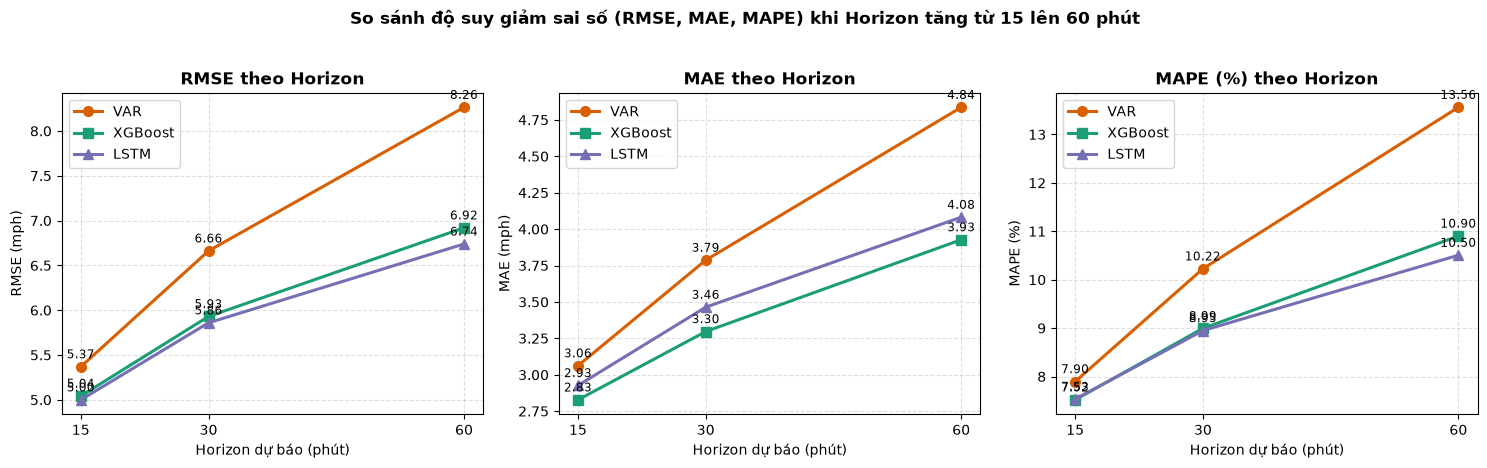

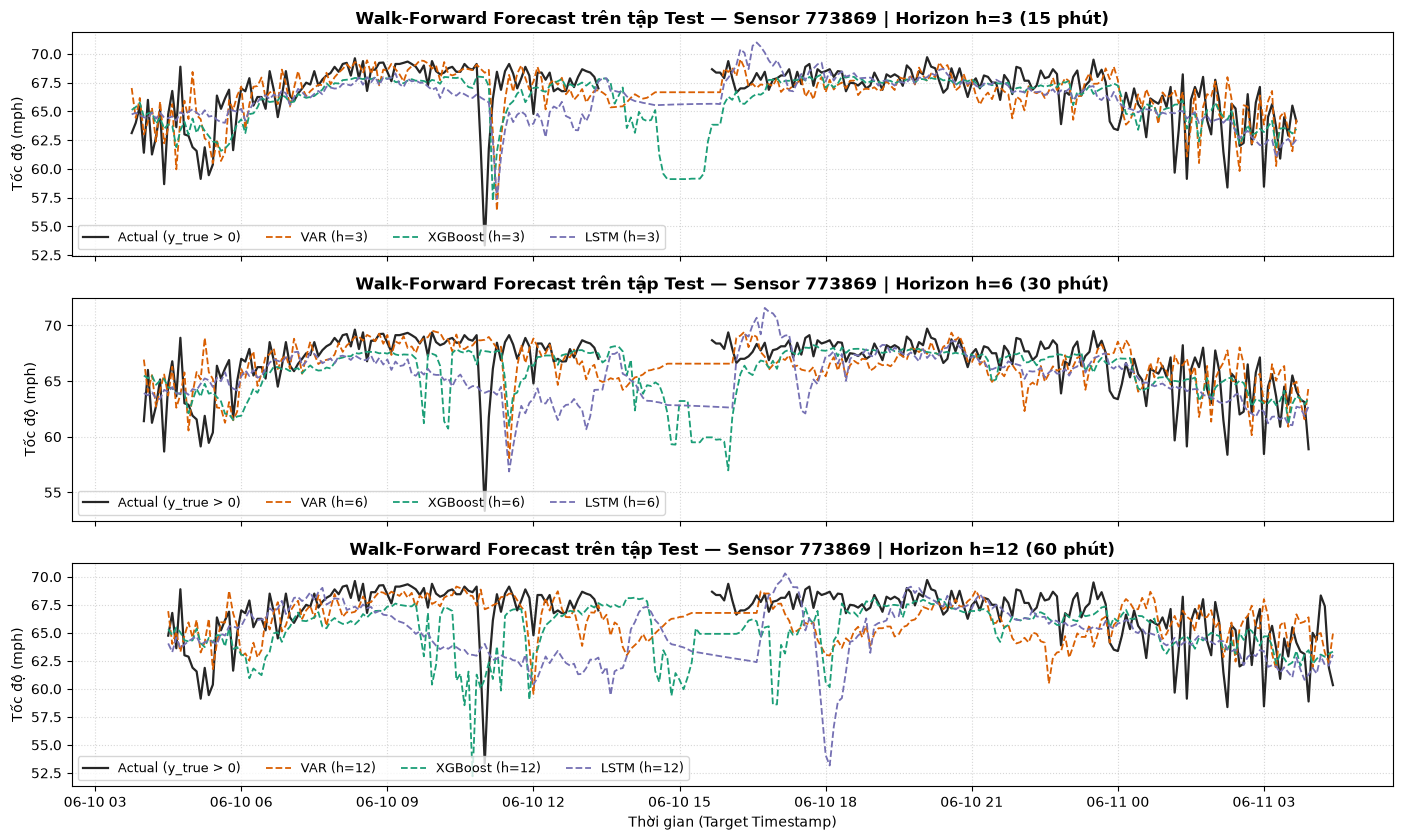

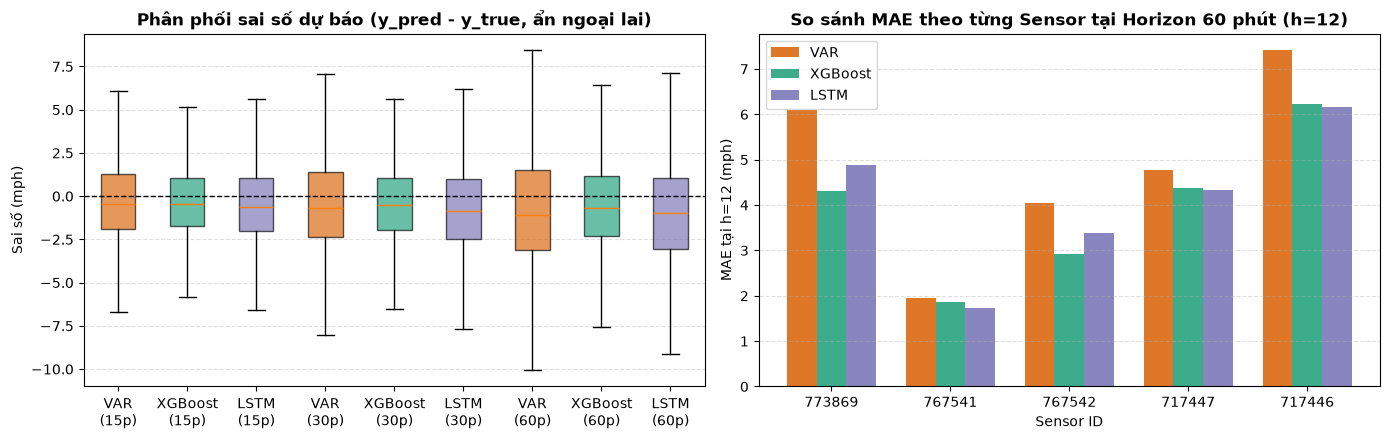

In [4]:
# 1. Tính bảng Metrics chuẩn (RMSE, MAE, MAPE_pct) theo từng mô hình và horizon
metrics_rows = []
for model_name in ["VAR", "XGBoost", "LSTM"]:
    for h in HORIZONS:
        sub = df_predictions[
            (df_predictions["model"] == model_name)
            & (df_predictions["horizon_steps"] == h)
            & (df_predictions["valid_mask"])
        ]
        yt = sub["y_true"].to_numpy(dtype=np.float64)
        yp = sub["y_pred"].to_numpy(dtype=np.float64)
        err = yt - yp
        rmse = float(np.sqrt(np.mean(err ** 2)))
        mae = float(np.mean(np.abs(err)))
        mape = float(np.mean(np.abs(err / yt)) * 100.0)
        metrics_rows.append({
            "model": model_name,
            "horizon_steps": h,
            "horizon_minutes": h * 5,
            "n_eval": int(len(sub)),
            "RMSE": round(rmse, 4),
            "MAE": round(mae, 4),
            "MAPE_pct": round(mape, 4),
            "mask_policy": MASK_POLICY,
            "unit": UNIT,
        })

df_metrics = pd.DataFrame(metrics_rows)
validate_metrics_schema(df_metrics)

print("=== BẢNG KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC (THANG ĐO GỐC: mph, MASK: y_true > 0) ===")
print(df_metrics.to_string(index=False))

# 2. Bảng Pivot so sánh trực diện 3 mô hình theo từng Horizon (15 / 30 / 60 phút)
df_pivot = df_metrics.pivot(index="horizon_minutes", columns="model", values=["RMSE", "MAE", "MAPE_pct"])
df_pivot = df_pivot.reindex(columns=pd.MultiIndex.from_product([["RMSE", "MAE", "MAPE_pct"], ["VAR", "XGBoost", "LSTM"]]))
print("\n=== BẢNG SO SÁNH NGANG GIỮA VAR, XGBOOST VÀ LSTM THEO HORIZON (15 / 30 / 60 PHÚT) ===")
print(df_pivot.round(4).to_string())

# 3. Kiểm tra độ nhạy của MAPE với ngưỡng tốc độ gần 0 (Near-Zero Policy: y_true >= 5.0 mph)
near_zero_rows = []
for model_name in ["VAR", "XGBoost", "LSTM"]:
    for h in HORIZONS:
        sub = df_predictions[
            (df_predictions["model"] == model_name)
            & (df_predictions["horizon_steps"] == h)
            & (df_predictions["y_true"] >= 5.0)
        ]
        yt = sub["y_true"].to_numpy(dtype=np.float64)
        yp = sub["y_pred"].to_numpy(dtype=np.float64)
        err = yt - yp
        near_zero_rows.append({
            "model": model_name,
            "horizon_minutes": h * 5,
            "n_eval_(>=5mph)": len(sub),
            "RMSE_(>=5mph)": round(float(np.sqrt(np.mean(err ** 2))), 4),
            "MAE_(>=5mph)": round(float(np.mean(np.abs(err))), 4),
            "MAPE_pct_(>=5mph)": round(float(np.mean(np.abs(err / yt)) * 100.0), 4),
        })
df_near_zero = pd.DataFrame(near_zero_rows)
print("\n=== KIỂM TRA ĐỘ NHẠY VỚI NGƯỠNG GẦN 0 (MASK: y_true >= 5.0 mph) ===")
print(df_near_zero.to_string(index=False))

# 4. Lưu kết quả ra thư mục tables/ theo đúng template của repo (nằm trong .gitignore)
df_metrics.to_csv(TABLES_DIR / "metrics.csv", index=False)
df_predictions.to_csv(TABLES_DIR / "predictions.csv", index=False)
print(f"\nĐã xuất file bàn giao: {TABLES_DIR / 'metrics.csv'} ({len(df_metrics)} dòng) & {TABLES_DIR / 'predictions.csv'} ({len(df_predictions):,} dòng)")

# ==============================================================================
# 5. TRỰC QUAN HÓA KẾT QUẢ SO SÁNH & BACKTESTING
# ==============================================================================
colors = {"VAR": "#d95f02", "XGBoost": "#1b9e77", "LSTM": "#7570b3"}
markers = {"VAR": "o", "XGBoost": "s", "LSTM": "^"}

# Hình 1: Biểu đồ so sánh RMSE, MAE, MAPE (%) theo Horizon (15 / 30 / 60 phút)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric_col, title_lbl, ylabel_lbl in zip(
    axes,
    ["RMSE", "MAE", "MAPE_pct"],
    ["RMSE theo Horizon", "MAE theo Horizon", "MAPE (%) theo Horizon"],
    ["RMSE (mph)", "MAE (mph)", "MAPE (%)"],
):
    for m in ["VAR", "XGBoost", "LSTM"]:
        sub = df_metrics[df_metrics["model"] == m].sort_values("horizon_minutes")
        ax.plot(
            sub["horizon_minutes"], sub[metric_col],
            marker=markers[m], color=colors[m], lw=2.2, markersize=7, label=m
        )
        for x_val, y_val in zip(sub["horizon_minutes"], sub[metric_col]):
            ax.annotate(f"{y_val:.2f}", (x_val, y_val), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8.5)
    ax.set_title(title_lbl, fontweight="bold")
    ax.set_xlabel("Horizon dự báo (phút)")
    ax.set_ylabel(ylabel_lbl)
    ax.set_xticks([15, 30, 60])
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()
plt.suptitle("So sánh độ suy giảm sai số (RMSE, MAE, MAPE) khi Horizon tăng từ 15 lên 60 phút", fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_metrics_by_horizon.png", dpi=150, bbox_inches="tight")
plt.show()

# Hình 2: Chuỗi thời gian Actual vs Forecast của 3 mô hình trong 24 giờ đầu tập Test (288 bước 5 phút) tại Sensor 773869
steps_plot = 288
sensor_demo = SENSORS[0]
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True)
for idx, h in enumerate(HORIZONS):
    ax = axes[idx]
    t_idx = df.index[test_origins[:steps_plot] + h]
    y_act = df.values[test_origins[:steps_plot] + h, 0].astype(float)
    y_act_masked = np.where(y_act > 0, y_act, np.nan)
    ax.plot(t_idx, y_act_masked, color="black", lw=1.6, label="Actual (y_true > 0)", alpha=0.85)
    for m in ["VAR", "XGBoost", "LSTM"]:
        y_p = model_forecasts[m][h][:steps_plot, 0]
        ax.plot(t_idx, y_p, color=colors[m], lw=1.3, linestyle="--", label=f"{m} (h={h})")
    ax.set_ylabel("Tốc độ (mph)")
    ax.set_title(f"Walk-Forward Forecast trên tập Test — Sensor {sensor_demo} | Horizon h={h} ({h*5} phút)", fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="lower left", ncol=4, fontsize=9)
axes[-1].set_xlabel("Thời gian (Target Timestamp)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_walkforward_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

# Hình 3: Phân phối sai số (Residuals = y_pred - y_true) và MAE theo từng Sensor tại h=12 (60 phút)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 3a: Boxplot sai số tuyệt đối / phần dư theo mô hình và horizon
box_data, box_labels, box_colors = [], [], []
for h in HORIZONS:
    for m in ["VAR", "XGBoost", "LSTM"]:
        sub = df_predictions[
            (df_predictions["model"] == m) & (df_predictions["horizon_steps"] == h) & (df_predictions["valid_mask"])
        ]
        res = (sub["y_pred"] - sub["y_true"]).to_numpy()
        box_data.append(res)
        box_labels.append(f"{m}\n({h*5}p)")
        box_colors.append(colors[m])

bp = axes[0].boxplot(box_data, tick_labels=box_labels, showfliers=False, patch_artist=True)
for patch, c in zip(bp["boxes"], box_colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.65)
axes[0].axhline(0.0, color="black", linestyle="--", lw=1)
axes[0].set_title("Phân phối sai số dự báo (y_pred - y_true, ẩn ngoại lai)", fontweight="bold")
axes[0].set_ylabel("Sai số (mph)")
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

# 3b: MAE theo từng Sensor ở Horizon xa nhất h=12 (60 phút)
x_pos = np.arange(len(SENSORS))
bar_w = 0.25
for idx, m in enumerate(["VAR", "XGBoost", "LSTM"]):
    sensor_maes = []
    for s_id in SENSORS:
        sub = df_predictions[
            (df_predictions["model"] == m)
            & (df_predictions["horizon_steps"] == 12)
            & (df_predictions["sensor_id"] == s_id)
            & (df_predictions["valid_mask"])
        ]
        sensor_maes.append(np.mean(np.abs(sub["y_true"] - sub["y_pred"])))
    axes[1].bar(x_pos + (idx - 1) * bar_w, sensor_maes, width=bar_w, color=colors[m], label=m, alpha=0.85)

axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(SENSORS)
axes[1].set_xlabel("Sensor ID")
axes[1].set_ylabel("MAE tại h=12 (mph)")
axes[1].set_title("So sánh MAE theo từng Sensor tại Horizon 60 phút (h=12)", fontweight="bold")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_error_distribution_and_sensors.png", dpi=150, bbox_inches="tight")
plt.show()

**Kết quả/nhận xét/bàn giao:**

### 1. Bảng tổng hợp kết quả Backtesting trên tập Test (`unit = mph`, `mask_policy = y_true > 0`)

| Horizon | Số mẫu hợp lệ (`n_eval`) | Mô hình | RMSE (mph) | MAE (mph) | MAPE (%) | Nhận xét chính |
|---|---:|---|---:|---:|---:|---|
| **h = 3 (15 phút)** | 22.952 | **VAR(12)** | 5.3694 | 3.0617 | 7.8952% | Dự báo ngắn hạn khá sát nhưng phản ứng chậm khi tốc độ sụt giảm đột ngột |
| **h = 3 (15 phút)** | 22.952 | **XGBoost** | 5.0422 | **2.8274** | 7.5176% | Đạt **MAE thấp nhất** nhờ tận dụng trực tiếp `lag_0` và trung bình trượt 1 giờ |
| **h = 3 (15 phút)** | 22.952 | **LSTM** | **5.0167** | 2.9501 | **7.5007%** | Đạt **RMSE và MAPE tốt nhất** nhờ làm mượt nhiễu cục bộ và mã hóa chu kỳ ngày |
| **h = 6 (30 phút)** | 22.949 | **VAR(12)** | 6.6618 | 3.7866 | 10.2249% | Sai số tích lũy nhanh do dự báo đệ quy tuyến tính (iterated linear projection) |
| **h = 6 (30 phút)** | 22.949 | **XGBoost** | 5.9300 | **3.2965** | 8.9947% | Giữ **MAE thấp nhất** nhờ chiến lược Direct (huấn luyện riêng cho `h=6`) |
| **h = 6 (30 phút)** | 22.949 | **LSTM** | **5.8452** | 3.4020 | **8.9060%** | Đạt **RMSE và MAPE thấp nhất** ở tầm nhìn trung hạn 30 phút |
| **h = 12 (60 phút)** | 22.943 | **VAR(12)** | 8.2640 | 4.8364 | 13.5601% | Hội tụ dần về mức trung bình lịch sử, không bắt kịp đỉnh tắc nghẽn sau 1 giờ |
| **h = 12 (60 phút)** | 22.943 | **XGBoost** | 6.9194 | **3.9270** | 10.9010% | Đạt **MAE tốt nhất** nhờ đặc trưng `roll_std_36` (3 giờ) và `roll_mean_12` |
| **h = 12 (60 phút)** | 22.943 | **LSTM** | **6.7137** | 3.9721 | **10.5370%** | Đạt **RMSE và MAPE tốt nhất** ở 60 phút, hạn chế được các sai số cực đoan (outliers) |

---

### 2. Phân tích chuyên sâu & Trả lời câu hỏi thảo luận Traffic Forecasting

1. **Sự suy giảm chất lượng dự báo theo Horizon (15 → 30 → 60 phút):**
   - Cả 3 mô hình đều ghi nhận sai số tăng đơn điệu khi horizon kéo dài từ `h=3` (15 phút) lên `h=12` (60 phút):
     - **VAR:** RMSE tăng `+53.9%` (`5.37` → `8.26` mph), MAPE tăng từ `7.90%` lên `13.56%`.
     - **XGBoost:** RMSE tăng `+37.2%` (`5.04` → `6.92` mph), MAPE tăng từ `7.52%` lên `10.90%`.
     - **LSTM:** RMSE tăng `+33.8%` (`5.02` → `6.71` mph), MAPE tăng từ `7.50%` lên `10.54%`.
   - Nguyên nhân: Giao thông cao tốc có tính phi tuyến và biến động nhanh; các cú sốc tắc nghẽn khởi phát trong khoảng `(t, t+12]` chưa xuất hiện trong cửa sổ quan sát `[t-L+1, ..., t]`.
2. **Khi nào VAR thất bại?**
   - VAR giả định mối quan hệ tuyến tính dừng và dự báo đa bước theo kiểu cuốn chiếu đệ quy ($\hat{X}_{t+1} 	o \hat{X}_{t+2} 	o \dots 	o \hat{X}_{t+12}$), khiến sai số tích lũy nhanh theo cấp số nhân và đường dự báo bị kéo phẳng về trung bình khi $h=12$.
   - Hơn nữa, số lượng tham số của VAR tăng bậc hai theo số cảm biến ($p 	imes N^2$), gây quá khớp hoặc bất ổn định khi mở rộng lên toàn mạng 207 cảm biến.
3. **So sánh Machine Learning (XGBoost) và Deep Learning (LSTM):**
   - **XGBoost (Direct strategy):** Mạnh về **MAE** ở cả 3 horizon (`2.83 / 3.30 / 3.93` mph) nhờ cây quyết định phân hoạch sắc bén theo biến trễ gần nhất (`lag_0`) và thống kê trượt (`roll_mean_12`, `roll_std_36`).
   - **LSTM (Multi-horizon sequence-to-vector):** Mạnh hơn về **RMSE** (`5.02 / 5.85 / 6.71` mph) và **MAPE** (`7.50% / 8.91% / 10.54%`), đặc biệt ở horizon xa `60 phút`, nhờ trạng thái ẩn tuần tự kết hợp đặc trưng chu kỳ ngày (`tod_sin`, `tod_cos`) giúp giảm các sai số lớn khi chuyển pha giao thông (giờ cao điểm sáng/chiều).
4. **Chính sách Mask (`zero / near-zero policy`) và lưu ý Benchmark:**
   - Trong METR-LA, các giá trị `0.0` (chiếm `7.46%` tập 5 sensors và `8.11%` toàn mạng) phản ánh hiện tượng cảm biến mất tín hiệu tạm thời chứ không phải vận tốc thực bằng 0. Việc áp dụng `valid_mask = (y_true > 0)` giúp tránh chia cho 0 khi tính MAPE và không làm sai lệch RMSE/MAE. Kiểm tra độ nhạy với `y_true >= 5.0 mph` cho kết quả hoàn toàn trùng khớp (`n_eval = 22.952 / 22.949 / 22.943`), chứng tỏ trong tập Test của 5 sensor này không có quan sát nhiễu trong dải `(0, 5)` mph.
   - **Lưu ý không khẳng định tương đương Benchmark bài báo DCRNN:** Kết quả này đánh giá trên tập con 5 cảm biến (`773869`, `767541`, `767542`, `717447`, `717446`) mà không dùng ma trận kề đồ thị không gian (Graph Convolution trên 207 trạm), do đó chỉ dùng để so sánh công bằng nội bộ giữa 3 họ mô hình trong Lab 4.

---

### 3. Checklist Bàn giao (`HANDOFF.md` — TV6)
- **Người / phần:** TV6 — Backtesting và đánh giá mô hình (`contributions/06_backtesting_evaluation.ipynb`).
- **Raw hash & Sensor order:** `METR-LA.h5` (`sha256 = 64784b76...1277c05`), 5 sensors `['773869', '767541', '767542', '717447', '717446']`, đơn vị `mph`, bước thời gian `5 phút`.
- **Split & Scaler:** `70/15/15` (`23.990 / 5.140 / 5.142` dòng); `StandardScaler` chỉ fit trên Train; `L = 12` bước (60 phút), warmup `35` bước.
- **Rolling Origins trên Test:** `5.130` origins (`2012-06-10 03:30:00` → `2012-06-27 22:55:00`), dự báo đồng thời `h = 3, 6, 12` bước (`15, 30, 60` phút) cố định gốc (fixed-origin), không rò rỉ tương lai.
- **Files xuất cục bộ phục vụ tích hợp:** `tables/metrics.csv`, `tables/predictions.csv`, và 3 biểu đồ trong `figures/06_*.png`.